---
title: "Target the Right Customers with Thinking Mode"
description: "Rank 200,000 bank customers by how likely they are to transact, then compare the simulated value of campaigns at selected budgets."
cookbookTags:
  - thinking mode
  - api
  - classification
authors:
  - name: Kürşat Kaya
    linkedin: https://www.linkedin.com/in/kursatkaya/
featured: true
---
A bank has 200,000 customers and wants to know which of them will make a particular
kind of transaction in the coming period. It is important for the bank to put the
right customers at the top of a list, because the list is what the business acts on. A campaign
reaches the first 1%, 5% or 20% of it, and everyone further down is never contacted.

The practical question is which model produces the best list for the campaign budgets the bank selects.

This notebook fits an XGBoost baseline and TabPFN-3.5 on the
[Santander Customer Transaction Prediction](https://www.kaggle.com/c/santander-customer-transaction-prediction)
dataset, then runs TabPFN-3.5-Thinking twice, once optimizing ROC AUC and once
average precision. It compares the four models the way a campaign would: by how many
transactors each list reaches at selected campaign budgets, and by the simulated net
value of a campaign at each of those budgets.

## Setup

Install the client, XGBoost and the other dependencies. In Colab, add `TABPFN_TOKEN` to Secrets; elsewhere, use your usual client authentication.

In [ ]:
%pip install -q --upgrade tabpfn-client==0.7.1 pandas==2.3.3 numpy==2.5.3 scikit-learn==1.9.0 matplotlib==3.11.2 pyarrow==25.0.1 huggingface-hub==1.31.0 xgboost==3.4.1

In [22]:
import os

try:
    from google.colab import userdata
except ImportError:
    pass
else:
    os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")

In [23]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download
from IPython.display import display
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

from xgboost import XGBClassifier
from tabpfn_client import TabPFNClassifier
from tabpfn_client.api_models import ModelVersion

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.width", 150)

## The data

We use the [BeyondArena](https://huggingface.co/datasets/TabArena/BeyondArena) copy
of the Kaggle training set: 200,000 customers, a binary target, and 200 anonymized
numeric features. BeyondArena adds two indicator columns per feature that encode
whether a value is unique in the dataset, a pattern the competition's top entries
relied on, which brings the width to 600 columns. The features have no names and
no documented meaning, so there is nothing to engineer by hand. Because the features
are anonymized, we compare the models without domain-specific feature engineering.

BeyondArena publishes fixed splits. We take the first fold of the first repetition:
133,333 customers to train on and 66,667 held out. Credit: Santander Bank via
[Kaggle](https://www.kaggle.com/competitions/santander-customer-transaction-prediction), used under the competition rules.

In [24]:
def download_file(filename):
    return hf_hub_download(
        "TabArena/BeyondArena",
        f"santander_customer_transaction_prediction/019d7373-33b4-7002-948b-c14d1fffe341/{filename}",
        repo_type="dataset", revision="88059a3f02ec4abb6ec24bbe0d1c0b7eed31485d",
    )

customers = pd.read_parquet(download_file("dataset.parquet"))
published_splits = json.loads(Path(download_file(
    "experiment_metadata.predictive-ml-splits-mold-v1.json"
)).read_text())["splits"]
train_idx, test_idx = published_splits["0"]["0"]

X_train = customers.iloc[train_idx].drop(columns="target")
y_train = customers.iloc[train_idx]["target"].to_numpy()
X_test = customers.iloc[test_idx].drop(columns="target")
y_test = customers.iloc[test_idx]["target"].to_numpy()
print(f"{len(X_train):,} training customers; {len(X_test):,} held-out customers; "
      f"{X_train.shape[1]} features; {y_train.mean():.1%} transact")

133,333 training customers; 66,667 held-out customers; 600 features; 10.0% transact


## What to measure

A campaign does not act on the whole ranking. It contacts the top of it, down to a
budget, so we evaluate every model at four selected campaign budgets: the top 1%, 5%,
10% and 20% of customers. At each budget we report:

- **Customers contacted** and **transactors captured**, as counts.
- **Precision**: the share of contacted customers who transact.
- **Lift**: precision divided by the 10% base rate, that is, how many times better
  the list does than contacting customers at random.
- **Net value** of the simulated campaign, under the cost and value assumptions set
  further down.

We also report ROC AUC, average precision, and log-loss. **ROC AUC**, the dataset's own
objective, measures ranking quality everywhere. **Average precision** weights the
top of the list, where campaigns operate. **Log-loss** measures whether the
probabilities are calibrated.

In [25]:
BUDGETS = [0.01, 0.05, 0.10, 0.20]


def formatted(frame, formats):
    """Format columns as text, so tables read the same in a notebook and on a static page."""
    return frame.apply(lambda col: col.map(formats[col.name].format) if col.name in formats else col)


def fit_and_score(model):
    """Fit on the training customers and return held-out scores and fit minutes."""
    started = time.perf_counter()
    model.fit(X_train, y_train)
    minutes = (time.perf_counter() - started) / 60
    probability = np.asarray(model.predict_proba(X_test), dtype=float)
    probability /= probability.sum(axis=1, keepdims=True)
    return probability[:, 1], minutes


def list_metrics(score, y_true):
    return {"ROC AUC": roc_auc_score(y_true, score),
            "Avg precision": average_precision_score(y_true, score),
            "Log-loss": log_loss(y_true, score)}


def campaign_table(scores, y_true, budgets, contact_cost, transaction_value):
    """Simulated campaign at each budget for every model, with the gap to the best model."""
    rows = []
    for budget in budgets:
        n_contacted = int(round(budget * len(y_true)))
        for name, score in scores.items():
            captured = int(y_true[np.argsort(-score)[:n_contacted]].sum())
            rows.append({"Budget": f"{budget:.0%}", "Model": name,
                         "Contacted": n_contacted,
                         "Transactors captured": captured,
                         "Precision": captured / n_contacted,
                         "Lift": captured / n_contacted / y_true.mean(),
                         "Net value (€)": captured * transaction_value - n_contacted * contact_cost})
    table = pd.DataFrame(rows)
    best = table.groupby("Budget")["Net value (€)"].transform("max")
    table["Opportunity cost (€)"] = best - table["Net value (€)"]
    return table.set_index(["Budget", "Model"])

## TabPFN-3.5

Every TabPFN model in this notebook is pinned to TabPFN-3.5 with
`create_default_for_version`, so TabPFN-3.5 and TabPFN-3.5-Thinking share the same checkpoint
and a change in the API's default model does not change the comparison.

On the API the fit itself takes a few seconds; the time
below is mostly uploading 133,000 rows.

In [26]:
scores, minutes = {}, {}
scores["TabPFN-3.5"], minutes["TabPFN-3.5"] = fit_and_score(
    TabPFNClassifier.create_default_for_version(ModelVersion.V3_5, random_state=0))
print(f"TabPFN-3.5: fit {minutes['TabPFN-3.5']:.1f} min")

TabPFN-3.5: fit 0.2 min


## Baseline: XGBoost

We include XGBoost as a conventional tabular baseline. 
We use shallow trees and a small learning rate, settings that suit many weak,
independent features, and fit once with them fixed. Nothing is tuned on the
held-out customers, so the comparison stays fair.

In [27]:
xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=2, subsample=0.8,
                    colsample_bytree=0.5, random_state=0, n_jobs=-1)
scores["XGBoost"], minutes["XGBoost"] = fit_and_score(xgb)
print(f"XGBoost: fit {minutes['XGBoost']:.1f} min")

XGBoost: fit 0.2 min


## TabPFN-3.5-Thinking with two objectives

Thinking mode changes what happens at fit time. Instead of a single forward pass, the
server runs an optimization over the training data against the metric named in
`thinking_metric`, then serves the result for every later prediction. We compare
roc_auc with average_precision to test whether optimizing for the top of the
ranking improves small campaigns. `"roc_auc"` rewards a good ranking everywhere in
the list; `"average_precision"` rewards getting the top of the list right, which is
the only part a small campaign ever sees.

We fit one model for each objective using the same "micro" effort level. thinking_effort controls the fit-time optimization budget; available levels depend on the client version and account access. On this dataset, each "micro" fit takes approximately 5 minutes.

In [28]:
EFFORT = "micro"

for metric in ["roc_auc", "average_precision"]:
    name = f"TabPFN-3.5-Thinking ({metric})"
    model = TabPFNClassifier.create_default_for_version(
        ModelVersion.V3_5, random_state=0, thinking_effort=EFFORT, thinking_metric=metric)
    scores[name], minutes[name] = fit_and_score(model)
    print(f"{name}: fit {minutes[name]:.1f} min")

TabPFN-3.5-Thinking (roc_auc): fit 5.7 min
TabPFN-3.5-Thinking (average_precision): fit 5.7 min


## Ranking quality

In [29]:
summary = pd.DataFrame({name: {**list_metrics(score, y_test), "Fit minutes": minutes[name]}
                        for name, score in scores.items()}).T
display(summary.round(4))

,ROC AUC,Avg precision,Log-loss,Fit minutes
TabPFN-3.5,0.8951,0.6025,0.2058,0.2037
XGBoost,0.8872,0.5880,0.2261,0.1777
TabPFN-3.5-Thinking (roc_auc),0.9074,0.6477,0.1950,5.6721
TabPFN-3.5-Thinking (average_precision),0.9074,0.6477,0.1951,5.6737


The chart puts the table on a common scale: each bar is a model's improvement over
XGBoost, in percent. For log-loss, where lower is better, the bar is the reduction.

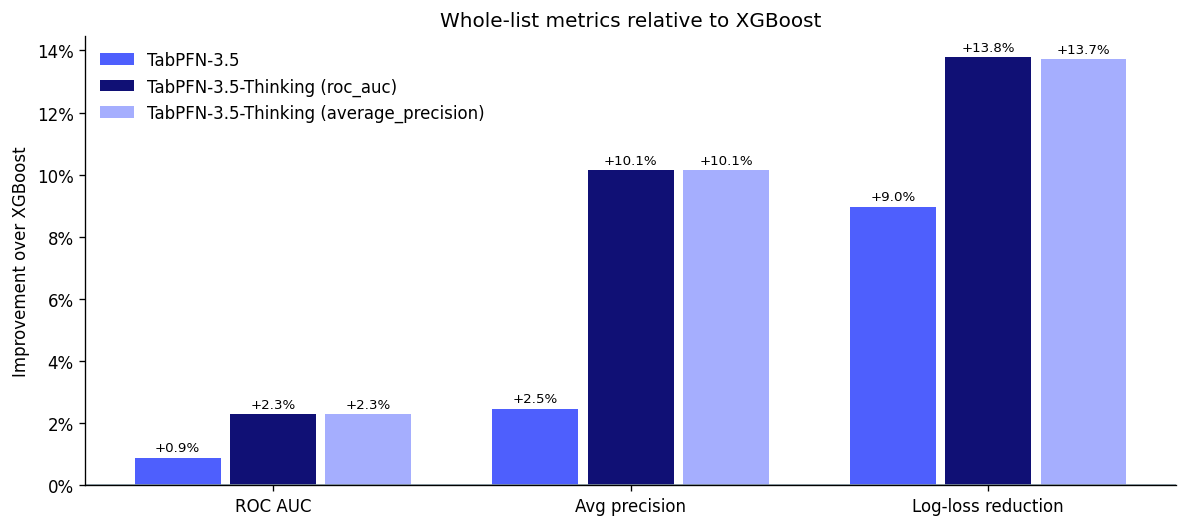

In [39]:
# Prior Labs palette: grey for XGBoost, Prior Blue for TabPFN-3.5, navy for Thinking.
colors = {"XGBoost": "#9CA3AF", "TabPFN-3.5": "#4E5FFD",
          "TabPFN-3.5-Thinking (roc_auc)": "#101075",
          "TabPFN-3.5-Thinking (average_precision)": "#A5AEFE"}

reference = summary.loc["XGBoost"]
improvement = pd.DataFrame({
    "ROC AUC": summary["ROC AUC"] / reference["ROC AUC"] - 1,
    "Avg precision": summary["Avg precision"] / reference["Avg precision"] - 1,
    "Log-loss reduction": 1 - summary["Log-loss"] / reference["Log-loss"],
}).drop(index="XGBoost")

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(improvement)
positions = np.arange(len(improvement.columns))
for k, (name, row) in enumerate(improvement.iterrows()):
    bars = ax.bar(positions + (k - (len(improvement) - 1) / 2) * width, row * 100, width * 0.9,
                  label=name, color=colors[name])
    ax.bar_label(bars, labels=[f"{v:+.1%}" for v in row], padding=2, fontsize=8)
ax.axhline(0, color="#90a4ae", linewidth=1)
ax.set_xticks(positions, improvement.columns)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:g}%")
ax.set(ylabel="Improvement over XGBoost", title="Whole-list metrics relative to XGBoost")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

Both TabPFN-3.5-Thinking objectives produce the same whole-list results: ROC AUC 0.9074 and average precision 0.6477, compared with 0.8951 and 0.6025 for TabPFN-3.5. XGBoost trails all TabPFN variants, with ROC AUC 0.8872 and average precision 0.5880. Relative to TabPFN-3.5, TabPFN-3.5-Thinking increases average precision from 0.6025 to 0.6477.

## Campaign assumptions

To turn a ranking into money we need two numbers, both set in the cell below:

- **Value per transaction**: what one transaction is worth to the bank. Default
  €100.
- **Cost per contact**: what one call, email or mailing costs. Default €2.

The net value of contacting the top *k* customers of a list is

net value = (transactors captured × value per transaction) − (customers contacted × cost per contact).

These defaults are illustrative, not Santander's figures. Change them to your own
and rerun the cells below. With them, a contact breaks even once 2% of the
contacted customers transact (cost ÷ value).

**This is a simulation based on predicted outcomes, not causal uplift.** It counts
every contacted customer who transacts as a transaction the campaign won. In
practice some of them would have transacted without being contacted, so the real
value of a campaign is lower and has to be measured with a randomized control
group. The numbers also cover only the 66,667 held-out customers, a third of the
customer base. Use them to compare models, not as a forecast of campaign revenue.

In [31]:
TRANSACTION_VALUE = 100.0  # assumed value of one transaction, in euros
CONTACT_COST = 2.0         # assumed cost of one contact, in euros

In [32]:
campaigns = campaign_table(scores, y_test, BUDGETS, CONTACT_COST, TRANSACTION_VALUE)
display(formatted(campaigns, {
    "Contacted": "{:,}", "Transactors captured": "{:,}", "Precision": "{:.1%}",
    "Lift": "{:.2f}", "Net value (€)": "€{:,.0f}", "Opportunity cost (€)": "€{:,.0f}"}))

Contacted Transactors captured Precision  Lift Net value (€) Opportunity cost (€)
Budget Model                                                                                                                    
1%     TabPFN-3.5                                    667                  612     91.8%  9.13       €59,866               €2,700
       XGBoost                                       667                  617     92.5%  9.21       €60,366               €2,200
       TabPFN-3.5-Thinking (roc_auc)                 667                  636     95.4%  9.49       €62,266                 €300
       TabPFN-3.5-Thinking (average_precision)       667                  639     95.8%  9.53       €62,566                   €0
5%     TabPFN-3.5                                  3,333                2,462     73.9%  7.35      €239,534              €15,700
       XGBoost                                     3,333                2,423     72.7%  7.23      €235,634              €19,600
       TabPFN-3.5-Thinking (roc_auc)               3,333                2,606     78.2%  7.78      €253,934               €1,300
       TabPFN-3.5-Thinking (average_precision)     3,333                2,619     78.6%  7.82      €255,234                   €0
10%    TabPFN-3.5                                  6,667                3,795     56.9%  5.66      €366,166              €18,500
       XGBoost                                     6,667                3,691     55.4%  5.51      €355,766              €28,900
       TabPFN-3.5-Thinking (roc_auc)               6,667                3,980     59.7%  5.94      €384,666                   €0
       TabPFN-3.5-Thinking (average_precision)     6,667                3,972     59.6%  5.93      €383,866                 €800
20%    TabPFN-3.5                                 13,333                5,088     38.2%  3.80      €482,134              €19,600
       XGBoost                                    13,333                4,964     37.2%  3.71      €469,734              €32,000
       TabPFN-3.5-Thinking (roc_auc)              13,333                5,284     39.6%  3.94      €501,734                   €0
       TabPFN-3.5-Thinking (average_precision)    13,333                5,281     39.6%  3.94      €501,434                 €300

TabPFN-3.5-Thinking produces the highest simulated value at every campaign budget. The two TabPFN-3.5-Thinking objectives are within a handful of transactors of each other at every budget, for example 639 and 636 in the top 1%, so neither objective has a meaningful edge here.

At the 10% budget, TabPFN-3.5-Thinking with ROC-AUC optimization produces €384,666 in simulated value, compared with €366,166 for TabPFN-3.5 and €355,766 for XGBoost. Under these assumptions, XGBoost’s opportunity cost is €28,900. At 20%, that gap grows to €32,000.

## The value of following TabPFN-3.5-Thinking

What does the better ranking add up to? Each bar shows simulated net-value uplift
relative to XGBoost at the same campaign budget: how much more a campaign that
contacts the top of the model's list is worth than the same campaign run from
XGBoost's list. We use the ROC AUC run of TabPFN-3.5-Thinking; the average precision
run is within a few transactors of it.

TabPFN-3.5-Thinking's campaign is worth 6.8–8.1% more than XGBoost's at the 5%, 10%
and 20% budgets, compared with 1.7–2.9% for TabPFN-3.5. At the top 20% that is
€501,734 against €469,734 for XGBoost. These figures cover the 66,667 held-out
customers, a third of the customer base, and assume the same €100 value and €2
cost per contact as above.

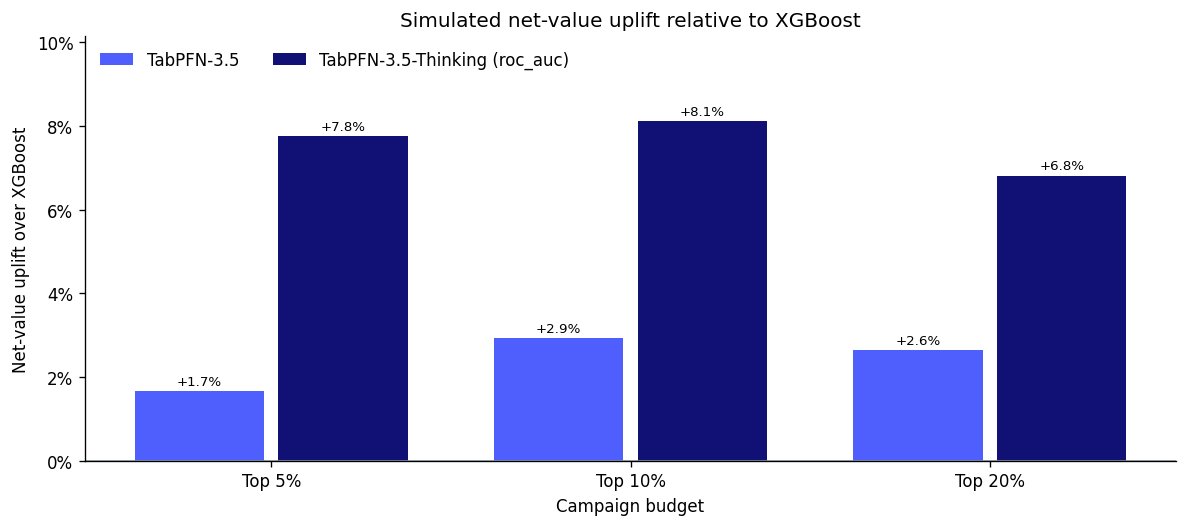

In [51]:
models = ["XGBoost", "TabPFN-3.5", "TabPFN-3.5-Thinking (roc_auc)"]
net = campaigns["Net value (€)"].unstack("Model").loc[["5%", "10%", "20%"], models]
uplift = net[models[1:]].div(net["XGBoost"], axis=0) - 1

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(uplift.columns)
positions = np.arange(len(uplift))
for k, name in enumerate(uplift.columns):
    bars = ax.bar(positions + (k - (len(uplift.columns) - 1) / 2) * width, uplift[name] * 100,
                  width * 0.9, label=name, color=colors[name])
    ax.bar_label(bars, labels=[f"{v:+.1%}" for v in uplift[name]], padding=2, fontsize=8)
ax.axhline(0, color="#90a4ae", linewidth=1)
ax.set_xticks(positions, [f"Top {b}" for b in uplift.index])
ax.yaxis.set_major_formatter(lambda y, _: f"{y:g}%")
ax.set(xlabel="Campaign budget", ylabel="Net-value uplift over XGBoost",
       title="Simulated net-value uplift relative to XGBoost")
ax.set_ylim(0, uplift.max().max() * 100 * 1.25)
ax.legend(frameon=False, loc="upper left", ncol=2)
fig.tight_layout()
plt.show()

To illustrate why even a relatively small model improvement can matter at scale, we
extrapolate the held-out results to a portfolio of two million customers. Under the
same assumptions, TabPFN-3.5-Thinking would generate approximately €867,000 more
simulated net value than XGBoost at a 10% campaign budget. The extrapolation is
linear: it assumes the wider portfolio looks like the held-out customers.

Extra value over XGBoost at a 10% budget, 2,000,000 customers: €866,996


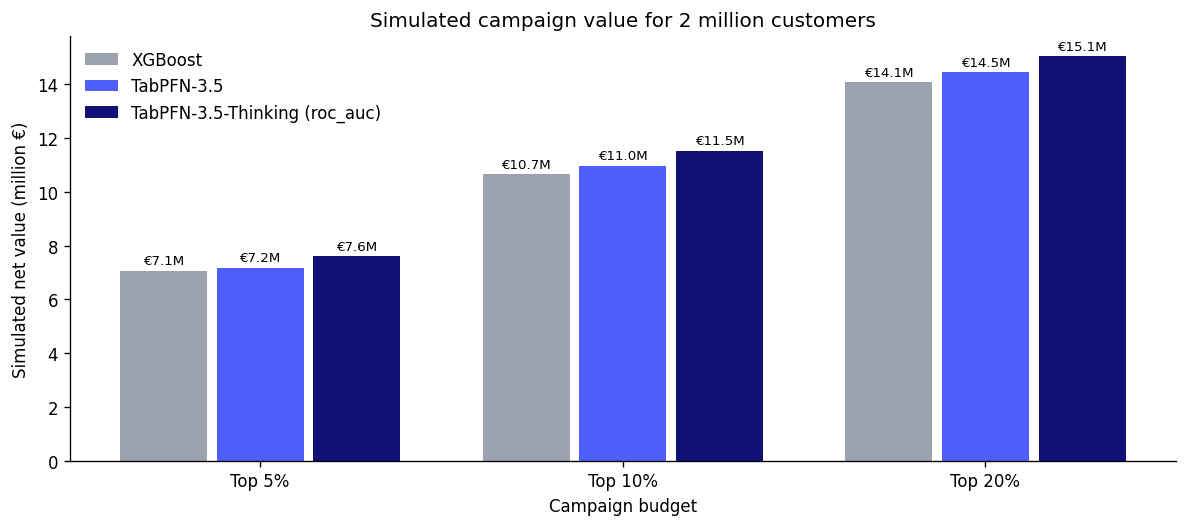

In [52]:
PORTFOLIO = 2_000_000
portfolio = net * PORTFOLIO / len(y_test)
gap = portfolio.loc["10%", "TabPFN-3.5-Thinking (roc_auc)"] - portfolio.loc["10%", "XGBoost"]
print(f"Extra value over XGBoost at a 10% budget, {PORTFOLIO:,} customers: €{gap:,.0f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(models)
positions = np.arange(len(portfolio))
for k, name in enumerate(models):
    bars = ax.bar(positions + (k - (len(models) - 1) / 2) * width, portfolio[name] / 1e6, width * 0.9,
                  label=name, color=colors[name])
    ax.bar_label(bars, labels=[f"€{v / 1e6:.1f}M" for v in portfolio[name]], padding=2, fontsize=8)
ax.set_xticks(positions, [f"Top {b}" for b in portfolio.index])
ax.set(xlabel="Campaign budget", ylabel="Simulated net value (million €)",
       title=f"Simulated campaign value for {PORTFOLIO / 1e6:g} million customers")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

## What this means for targeting

TabPFN-3.5-Thinking captures more transactors and produces the highest simulated net value at all four tested campaign budgets. At a 10% budget, it produces €384,666 on the 66,667 held-out customers: €18,500 more than TabPFN-3.5 and €28,900 more than XGBoost.

The Thinking objective makes little practical difference in this experiment. Optimizing ROC AUC or average precision changes the number of captured transactors by no more than 13 at any tested budget. Here, most of the improvement comes from using Thinking rather than selecting between these two objectives.

At larger scale, a small per-customer improvement can become material. If the held-out results scaled linearly to two million customers, the 10% campaign would produce approximately €867,000 more simulated value with Thinking than with XGBoost.

This extrapolation assumes the same transaction rate, model performance, €100 transaction value, and €2 contact cost. It is a propensity-based simulation, not an estimate of causal campaign impact.

## Takeaways

- TabPFN-3.5-Thinking produces the highest simulated campaign value at every tested budget.

- At a 10% budget, Thinking adds €18,500 over TabPFN-3.5 and €28,900 over XGBoost on the held-out customers.

- Under the same assumptions, the advantage over XGBoost would correspond to approximately €867,000 across a two-million-customer portfolio.

- ROC AUC and average-precision optimization give nearly identical results here; enabling Thinking matters more than choosing between the two objectives.